<a href="https://colab.research.google.com/github/scardenol/Numerical_Analysis_2026/blob/main/Taller%203/3_fem_1d_malla_no_uniforme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller 3 — Punto 3: Elementos finitos en 1D con malla no uniforme

Enunciado oficial

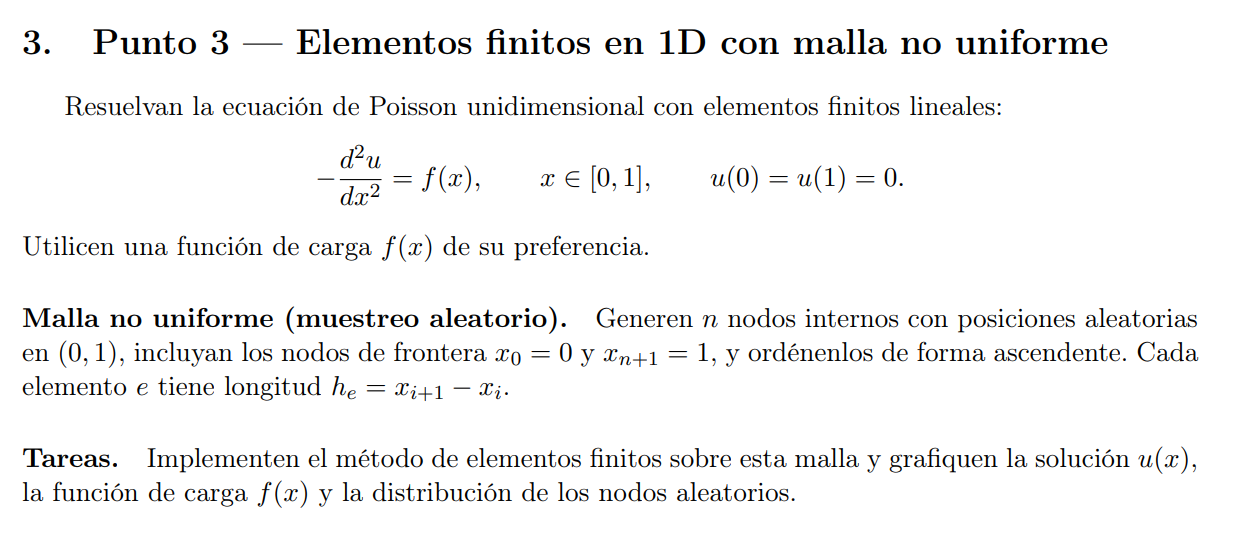

**Idea.** Resolver la ecuación de Poisson unidimensional $-u''=f$ en $[0,1]$, con $u(0)=u(1)=0$, usando elementos finitos lineales sobre una malla **no uniforme** (nodos interiores aleatorios). El método se programa tal como se vio en clase: matriz de conectividad, rigidez local, carga local con cuadratura de Gauss y ensamblaje. Luego se grafica la solución $u(x)$, la carga $f(x)$ y la distribución de los nodos aleatorios.

**Outline del notebook:**

1. Malla no uniforme y matriz de conectividad.
2. Matrices locales y ensamblaje de $K$ y $\mathbf b$.
3. Condiciones de frontera: imposición manual.
4. (Extra) Validar el código con el ejemplo de clase $-u''=x$ con $u=\frac{x-x^3}{6}$: se valida el código y se visualizan la conectividad, $K$ y $\mathbf b$ de la última iteración.
5. El problema del taller, con $f(x)=\pi^2\sin(\pi x)$.
6. (Extra) ¿qué pasa con otras cargas $f(x)$ (escalón, impulso, rampa, seno y ruido blanco)? Como cuando uno testea un sistema misterioso.

### Del problema fuerte al débil

Se multiplica $-u''=f$ por una función de prueba $\phi\in V$ (con $\phi(0)=\phi(1)=0$) y se integra por partes. El término de frontera $u'\phi\,\big|_0^1$ se anula:

$$
\int_\Omega u'\phi'\,dx=\int_\Omega f\phi\,dx\quad\forall\phi\in V \qquad\Longleftrightarrow\qquad (u',\phi')=(f,\phi).
$$

Con $u_h=\sum_i u_i\phi_i$ y $\phi=\phi_j$ (funciones sombrero o triangulares) se llega al sistema $K\mathbf u=\mathbf b$, donde

$$
K_{ij}=\int_\Omega\phi_i'\phi_j'\,dx=\sum_{e}K^{(e)}_{ij},\qquad b_i=\int_\Omega f\phi_i\,dx=\sum_e b_i^{(e)} .
$$

### Elemento canónico

Para el elemento $e=[a,b]$ con $h_e=b-a$ se usa $\xi\in[-1,1]$:

$$
x=\frac{a+b}{2}+\frac{b-a}{2}\xi,\qquad J_e=\frac{dx}{d\xi}=\frac{h_e}{2},\qquad
\hat\phi_0=\frac{1-\xi}{2},\quad\hat\phi_1=\frac{1+\xi}{2},\qquad
\phi_i'=\frac{1}{J_e}\frac{d\hat\phi}{d\xi}.
$$

Con esto, las contribuciones locales son

$$
\tilde K^{(e)}=\frac{1}{h_e}\begin{bmatrix}1&-1\\-1&1\end{bmatrix},\qquad
\tilde b^{(e)}_r=\int_{-1}^{1}f(x(\xi))\,\hat\phi_r(\xi)\,J_e\,d\xi\approx J_e\sum_{k=1}^m w_k\,f(x(\xi_k))\,\hat\phi_r(\xi_k),
$$

donde la cuadratura de Gauss–Legendre usa

<div align="center">

| $m$ | $\xi_k$ | $w_k$ |
|---|---|---|
| 1 | $0$ | $2$ |
| 2 | $\pm1/\sqrt3$ | $1,\ 1$ |
| 3 | $0,\ \pm\sqrt{3/5}$ | $8/9,\ 5/9,\ 5/9$ |

</div>

### Ensamblaje

Con la conectividad $q(e,r)$ (nodo global del nodo local $r$ del elemento $e$; aquí $q(e,r)=e+r$ con $r=0,1$):

$$
K_{q(e,r),\,q(e,s)}\mathrel{+}=\tilde K^{(e)}_{r,s},\qquad b_{q(e,r)}\mathrel{+}=\tilde b^{(e)}_r .
$$

**Algoritmo:**

1. Inicializar $K=0$, $\mathbf b=0$ (un valor por nodo).
2. Para cada elemento: calcular $h_e$, $\tilde K^{(e)}$ y $\tilde{\mathbf b}^{(e)}$, y sumarlos a $K$ y $\mathbf b$ con $i=q(e,r)$, $j=q(e,s)$.
3. Imponer las condiciones esenciales (de frontera) si es necesario.
4. Resolver $K\mathbf u=\mathbf b$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, TwoSlopeNorm
from matplotlib.patches import Rectangle
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# ------------------------------- Colores ----------------------------------
AZUL    = ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
NARANJA = ["#fbdcbc", "#f7b676", "#ee8a35", "#d9640f", "#b0480a", "#82330a", "#5a2208"]
TINTA, GRIS = "#2b2b28", "#6e6e69"
cmap_div = LinearSegmentedColormap.from_list("div", [NARANJA[3], "#ffffff", AZUL[3]])  # negativo = naranja, positivo = azul

## 1. Malla no uniforme y matriz de conectividad

- Se generan $n$ nodos interiores con posiciones aleatorias (uniformes) en $(0,1)$, se agregan los nodos de frontera $x_0=0$ y $x_{n+1}=1$, y se ordena todo de forma ascendente.
- Cada elemento $e$ tiene longitud $h_e=x_{e+1}-x_e$ (distinta en cada elemento: de ahí que la malla sea no uniforme).
- La **matriz de conectividad** guarda, para cada elemento $e$ (fila), los nodos globales de sus dos extremos (columnas $r=0,1$): $q(e,r)=e+r$.

In [2]:
def generar_malla(n, semilla=None):
    # n nodos interiores aleatorios + nodos de frontera (0 y 1), en orden ascendente
    rng = np.random.default_rng(semilla)
    interiores = rng.uniform(0.0, 1.0, n)
    return np.sort(np.concatenate(([0.0], interiores, [1.0])))


def conectividad(nodos):
    # Matriz de conectividad (Ne x 2): fila e = [q(e,0), q(e,1)] = [e, e+1]
    Ne = len(nodos) - 1
    return np.column_stack([np.arange(Ne), np.arange(1, Ne + 1)])

## 2. Matrices locales y ensamblaje

- `rigidez_local(h)` devuelve $\tilde K^{(e)}$ y `carga_local(...)` devuelve $\tilde{\mathbf b}^{(e)}$ con cuadratura de Gauss en el elemento canónico.
- `ensamblar(...)` recorre los elementos y suma cada contribución local en $K$ y $\mathbf b$ usando la conectividad. Si `guardar_historia=True`, guarda una "foto" de $K$ y $\mathbf b$ después de cada iteración (para poder visualizarlas).
- `carga_puntual(...)` se usa solo en el extra del impulso (Dirac): en la forma débil, $f=\delta(x-x_0)$ da $b_i=\phi_i(x_0)$.

In [3]:
def rigidez_local(h):
    # K~(e) = (1/h_e) [[1, -1], [-1, 1]]
    return (1.0 / h) * np.array([[1.0, -1.0], [-1.0, 1.0]])


def carga_local(f, xa, xb, xi, w):
    # b~_r(e) = J_e * sum_k w_k f(x(xi_k)) phi_hat_r(xi_k)
    J = (xb - xa) / 2.0
    x = (xa + xb) / 2.0 + J * xi              # elemento canónico -> elemento físico
    phi0, phi1 = (1.0 - xi) / 2.0, (1.0 + xi) / 2.0
    fx = f(x)
    return J * np.array([np.sum(w * fx * phi0), np.sum(w * fx * phi1)])


def ensamblar(nodos, f=None, m=3, guardar_historia=False):
    # Devuelve K, b, la matriz de conectividad y (opcional) la historia de iteraciones.
    # Si f es None, b queda en ceros (para sumar una carga puntual después).
    N = len(nodos)
    conn = conectividad(nodos)
    K = np.zeros((N, N))
    b = np.zeros(N)
    xi, w = np.polynomial.legendre.leggauss(m)     # puntos y pesos de Gauss-Legendre
    historia = []

    for e in range(conn.shape[0]):
        xa, xb = nodos[conn[e, 0]], nodos[conn[e, 1]]
        h = xb - xa
        Ke = rigidez_local(h)
        be = carga_local(f, xa, xb, xi, w) if f is not None else np.zeros(2)
        for r in range(2):
            i = conn[e, r]                         # i = q(e, r)
            b[i] += be[r]
            for s in range(2):
                j = conn[e, s]                     # j = q(e, s)
                K[i, j] += Ke[r, s]
        if guardar_historia:
            historia.append(dict(e=e, h=h, Ke=Ke, be=be, K=K.copy(), b=b.copy()))
    return K, b, conn, historia


def carga_puntual(nodos, x0, amplitud=1.0):
    # Vector de carga de f = amplitud * delta(x - x0):  b_i = amplitud * phi_i(x0)
    b = np.zeros(len(nodos))
    e = np.clip(np.searchsorted(nodos, x0) - 1, 0, len(nodos) - 2)
    xa, xb = nodos[e], nodos[e + 1]
    b[e] = amplitud * (xb - x0) / (xb - xa)
    b[e + 1] = amplitud * (x0 - xa) / (xb - xa)
    return b

## 3. Condiciones de frontera: imposición manual

Después de ensamblar, $K$ es **singular** (todavía no sabe que $u(0)=u(1)=0$), así que hay que imponer las condiciones esenciales (Dirichlet) a mano. Para cada nodo de frontera $i$ con valor conocido $u_i=g_i$ se modifica el sistema completo así:

<div align="center">

| Paso | Operación | Para qué |
|---|---|---|
| 1 | $\mathbf b\leftarrow\mathbf b-K_{:,i}\,g_i$ | pasar al lado derecho lo que aporta el valor conocido |
| 2 | fila $i$ y columna $i$ de $K$ $\leftarrow 0$ | desacoplar el nodo (y conservar la simetría de $K$) |
| 3 | $K_{ii}\leftarrow1$ | la fila $i$ queda como la ecuación $u_i=g_i$ |
| 4 | $b_i\leftarrow g_i$ | valor impuesto |

</div>

Es la misma idea de la "fila de la identidad" del Punto 1. El sistema sigue siendo de tamaño $N\times N$ y se resuelve con `np.linalg.solve` (en vez de calcular explícitamente $K^{-1}$).

> Nota: con $g_i=0$ el paso 1 no cambia nada, pero se deja para que el código también funcione con $g\neq0$ (más abajo se verifica).

In [4]:
def imponer_dirichlet(K, b, nodos_dir, valores):
    # Imposición manual de u[nodos_dir] = valores sobre el sistema completo (devuelve copias)
    K, b = K.copy(), b.copy()
    for i, g in zip(nodos_dir, valores):
        b -= K[:, i] * g        # 1) lo conocido pasa al lado derecho
        K[i, :] = 0.0           # 2) se anulan fila y columna i
        K[:, i] = 0.0
        K[i, i] = 1.0           # 3) fila de la identidad
        b[i] = g                # 4) valor impuesto
    return K, b


def resolver(K, b, g_izq=0.0, g_der=0.0):
    # Impone u(0) = g_izq, u(1) = g_der y resuelve K u = b
    N = len(b)
    Kb, bb = imponer_dirichlet(K, b, [0, N - 1], [g_izq, g_der])
    return np.linalg.solve(Kb, bb)

## 4. Extra (por diversión): validar el código con el ejemplo de clase: $-u''=x$

Antes de pasar al problema del taller se valida el código con el ejemplo de clase:

$$-u''=x,\quad x\in(0,1),\quad u(0)=u(1)=0\qquad\Longrightarrow\qquad u(x)=\frac{x-x^3}{6}.$$

- Se usa una malla aleatoria pequeña (5 nodos interiores) para que las matrices se puedan visualizar.
- Se guarda la historia del ensamblaje y se visualiza la **última iteración**, es decir, el estado de $K$ y $\mathbf b$ justo después de sumar el último elemento (el cuadrito naranja marca el bloque de ese elemento).

In [5]:
n_ej = 5
nodos_ej = generar_malla(n_ej, semilla=3)
f_ej = lambda x: x
u_ej = lambda x: (x - x**3) / 6.0

K_ej, b_ej, conn_ej, hist_ej = ensamblar(nodos_ej, f_ej, m=2, guardar_historia=True)

tabla_nodos = pd.DataFrame({"x_i": nodos_ej})
tabla_nodos.index.name = "nodo i"
tabla_elem = pd.DataFrame({"q(e,0)": conn_ej[:, 0], "q(e,1)": conn_ej[:, 1],
                           "h_e": [it["h"] for it in hist_ej]})
tabla_elem.index.name = "elemento e"
display(tabla_nodos.round(4).T)
display(tabla_elem.round(4))

nodo i,0,1,2,3,4,5,6
x_i,0.0,0.0856,0.0941,0.2368,0.5822,0.8013,1.0


,"q(e,0)","q(e,1)",h_e
elemento e,,,
0,0,1,0.0856
1,1,2,0.0085
2,2,3,0.1427
3,3,4,0.3454
4,4,5,0.2191
5,5,6,0.1987


/tmp/ipykernel_610/3543067993.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


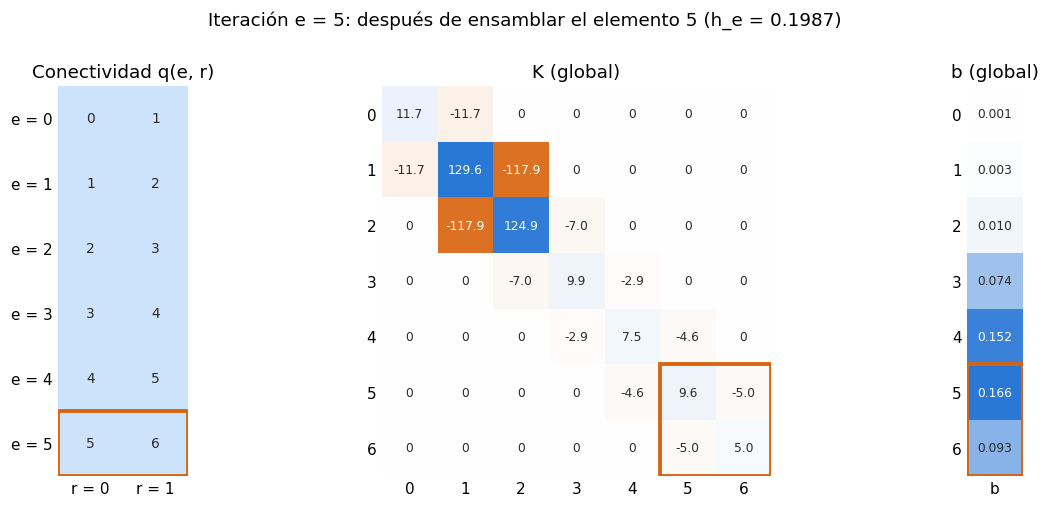

In [6]:
def dibujar_matriz(ax, A, titulo, filas, cols, fmt="{:.1f}", vmax=None):
    # Mapa de calor anotado de una matriz pequeña (diverging centrado en 0)
    vmax = vmax if vmax else (np.abs(A).max() or 1.0)
    ax.imshow(A, cmap=cmap_div, norm=TwoSlopeNorm(0, -vmax, vmax), aspect="equal")
    for (r, c), v in np.ndenumerate(A):
        ax.text(c, r, "0" if v == 0 else fmt.format(v), ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 * vmax else TINTA)
    ax.set_xticks(range(A.shape[1])); ax.set_xticklabels(cols)
    ax.set_yticks(range(A.shape[0])); ax.set_yticklabels(filas)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(titulo)


def dibujar_conectividad(ax, conn, resaltar=None):
    Ne = conn.shape[0]
    ax.imshow(np.zeros(conn.shape), cmap=ListedColormap([AZUL[0]]), vmin=0, vmax=1, aspect="equal")
    for (e, r), v in np.ndenumerate(conn):
        ax.text(r, e, str(v), ha="center", va="center", fontsize=9, color=TINTA)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["r = 0", "r = 1"])
    ax.set_yticks(range(Ne)); ax.set_yticklabels([f"e = {e}" for e in range(Ne)])
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    if resaltar is not None:
        ax.add_patch(Rectangle((-0.5, resaltar - 0.5), 2, 1, fill=False, ec=NARANJA[3], lw=2.5))
    ax.set_title("Conectividad q(e, r)")


def dibujar_iteracion(it, conn, vmax_K):
    e = it["e"]
    N = it["K"].shape[0]
    nodos_txt = [f"{i}" for i in range(N)]
    fig, ax = plt.subplots(1, 3, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[2.4, 7.4, 1.5], wspace=0.25))
    dibujar_conectividad(ax[0], conn, resaltar=e)
    dibujar_matriz(ax[1], it["K"], "K (global)", nodos_txt, nodos_txt, vmax=vmax_K)
    dibujar_matriz(ax[2], it["b"].reshape(-1, 1), "b (global)", nodos_txt, ["b"], fmt="{:.3f}")
    ax[1].add_patch(Rectangle((e - 0.5, e - 0.5), 2, 2, fill=False, ec=NARANJA[3], lw=2.5))
    ax[2].add_patch(Rectangle((-0.5, e - 0.5), 1, 2, fill=False, ec=NARANJA[3], lw=2.5))
    fig.suptitle(f"Iteración e = {e}: después de ensamblar el elemento {e} (h_e = {it['h']:.4f})", y=1.03)
    plt.tight_layout()
    plt.show()


ITER = -1       # -1 = última iteración; cambie a 0, 1, 2, ... para ver las anteriores
vmax_K = np.abs(hist_ej[-1]["K"]).max()
dibujar_iteracion(hist_ej[ITER], conn_ej, vmax_K)

Como es la última iteración, $K$ y $\mathbf b$ de la figura son las matrices globales completas **antes** de imponer la frontera. Se nota que:

- $K$ es **tridiagonal y simétrica**: cada nodo solo interactúa con sus vecinos. Fuera de las esquinas, la diagonal es $\frac{1}{h_{e-1}}+\frac{1}{h_e}$ y las codiagonales son $-\frac{1}{h_e}$ (por eso los valores cambian de un elemento a otro: la malla no es uniforme).
- Las filas de $K$ suman cero (las funciones constantes están en el núcleo de $K$), lo que confirma que $K$ es singular hasta que se imponen las condiciones de frontera.

Ahora se impone la frontera sobre el sistema completo y se resuelve:

/tmp/ipykernel_610/2832051685.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


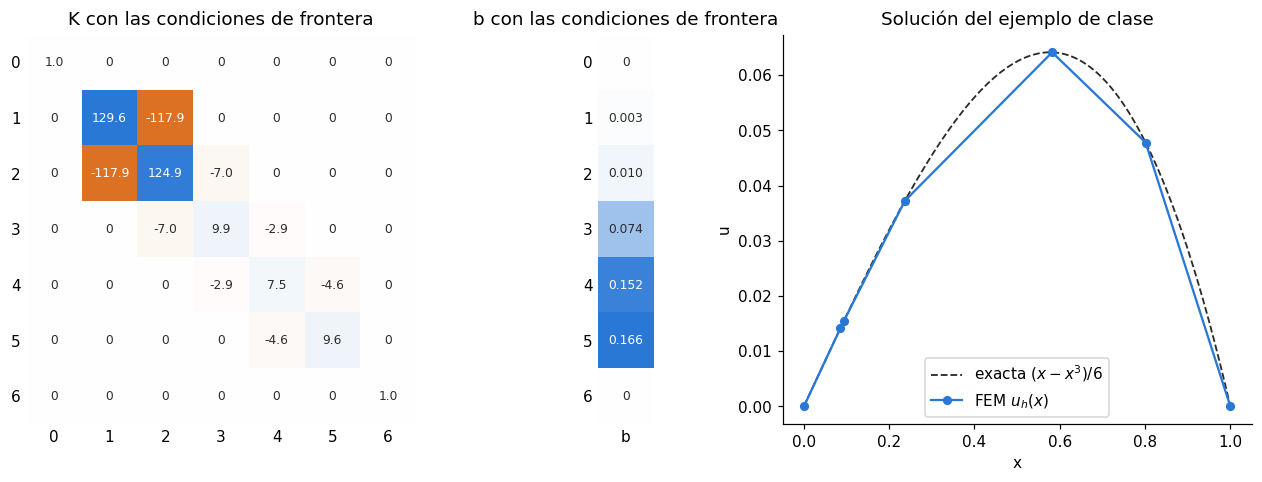

Error máximo en los nodos contra la solución exacta: 1.56e-17


In [7]:
N_ej = len(b_ej)
K_bc, b_bc = imponer_dirichlet(K_ej, b_ej, [0, N_ej - 1], [0.0, 0.0])
u_h_ej = np.linalg.solve(K_bc, b_bc)

nodos_txt = [f"{i}" for i in range(N_ej)]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[7.4, 1.5, 7.0], wspace=0.3))
dibujar_matriz(ax[0], K_bc, "K con las condiciones de frontera", nodos_txt, nodos_txt, vmax=vmax_K)
dibujar_matriz(ax[1], b_bc.reshape(-1, 1), "b con las condiciones de frontera", nodos_txt, ["b"], fmt="{:.3f}")

xx = np.linspace(0, 1, 400)
ax[2].plot(xx, u_ej(xx), "--", color=TINTA, lw=1.2, label=r"exacta $(x-x^3)/6$")
ax[2].plot(nodos_ej, u_h_ej, "o-", color=AZUL[3], ms=5, label=r"FEM $u_h(x)$")
ax[2].set(title="Solución del ejemplo de clase", xlabel="x", ylabel="u")
ax[2].legend()
plt.tight_layout()
plt.show()

print(f"Error máximo en los nodos contra la solución exacta: {np.max(np.abs(u_h_ej - u_ej(nodos_ej))):.2e}")

Las filas y columnas de los nodos $0$ y $N-1$ quedaron como la identidad con $b=0$, así que $u_0=u_{N-1}=0$, y el bloque interior de $K$ no cambió.

**Verificaciones del método de imposición:**
1. Es equivalente a eliminar las incógnitas de frontera y resolver solo el bloque interior de $K$ (sistema reducido de tamaño $(N-2)\times(N-2)$).
2. Funciona con valores de frontera distintos de cero: $-u''=0$, $u(0)=1$, $u(1)=3$ tiene solución $u=1+2x$.

In [8]:
# (1) Sistema completo con filas de identidad vs. sistema reducido (sin las incógnitas de frontera)
u_red = np.zeros(N_ej)
u_red[1:-1] = np.linalg.solve(K_ej[1:-1, 1:-1], b_ej[1:-1])
print(f"Diferencia entre ambos métodos: {np.max(np.abs(u_h_ej - u_red)):.2e}")

# (2) Frontera no homogénea: -u'' = 0, u(0) = 1, u(1) = 3  ->  u = 1 + 2x
K0, b0, _, _ = ensamblar(nodos_ej, None)
u_g = resolver(K0, b0, g_izq=1.0, g_der=3.0)
print(f"Error con g != 0 contra u = 1 + 2x: {np.max(np.abs(u_g - (1 + 2 * nodos_ej))):.2e}")

Diferencia entre ambos métodos: 0.00e+00
Error con g != 0 contra u = 1 + 2x: 1.33e-15


## 5. El problema del taller

Se escoge la carga $f(x)=\pi^2\sin(\pi x)$, cuya solución exacta es $u(x)=\sin(\pi x)$ (sirve para comprobar el código). Se usan $n=20$ nodos interiores aleatorios y cuadratura de Gauss con $m=3$ puntos.

In [9]:
n = 20 # número de nodos interiores aleatorios
nodos = generar_malla(n, semilla=42) # generar malla con semilla para reproducibilidad

f = lambda x: np.pi**2 * np.sin(np.pi * x) # f como función lambda
u_exacta = lambda x: np.sin(np.pi * x) # solución u exacta como función lambda

K, b, conn, _ = ensamblar(nodos, f, m=3) # ensamblar
u = resolver(K, b) # resolver

h = np.diff(nodos)
print(f"Nodos: {len(nodos)}  |  elementos: {len(h)}")
print(f"h_min = {h.min():.4f},  h_max = {h.max():.4f}")
print(f"Error máximo en los nodos contra la solución exacta: {np.max(np.abs(u - u_exacta(nodos))):.2e}")

Nodos: 22  |  elementos: 21
h_min = 0.0045,  h_max = 0.1436
Error máximo en los nodos contra la solución exacta: 3.65e-09


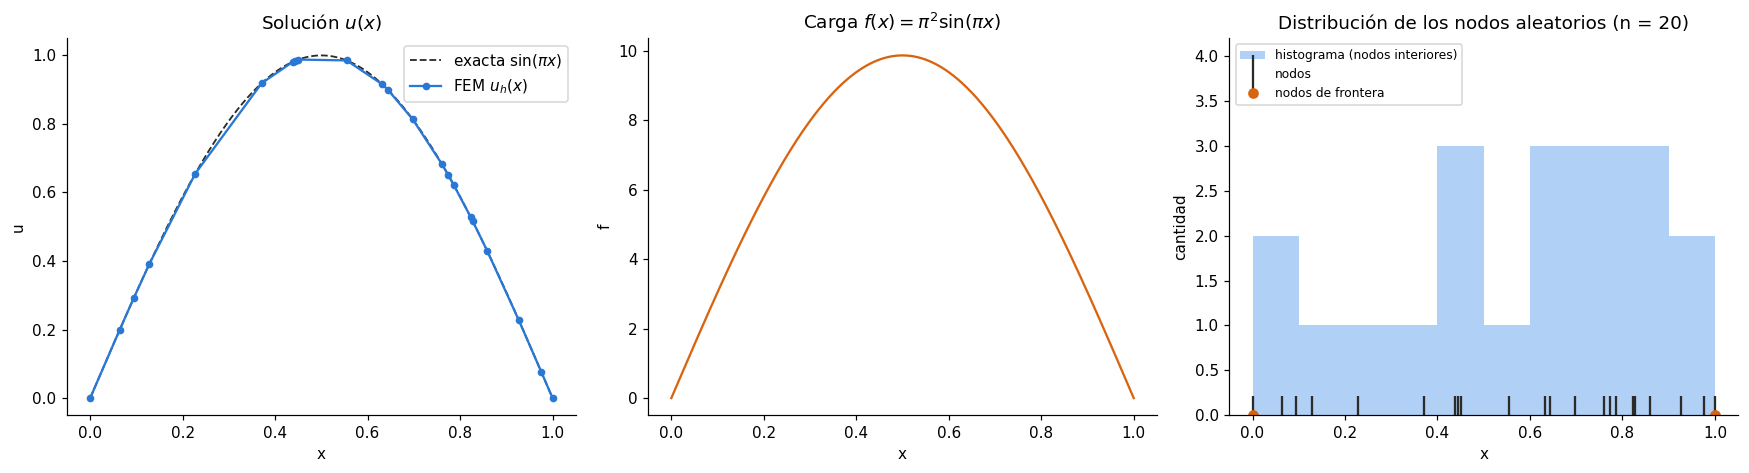

In [10]:
xx = np.linspace(0, 1, 500)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

# (1) solución u(x)
ax[0].plot(xx, u_exacta(xx), "--", color=TINTA, lw=1.2, label=r"exacta $\sin(\pi x)$")
ax[0].plot(nodos, u, "o-", color=AZUL[3], ms=4, label=r"FEM $u_h(x)$")
ax[0].set(title="Solución $u(x)$", xlabel="x", ylabel="u")
ax[0].legend()

# (2) carga f(x)
ax[1].plot(xx, f(xx), color=NARANJA[3])
ax[1].set(title=r"Carga $f(x)=\pi^2\sin(\pi x)$", xlabel="x", ylabel="f")

# (3) distribución de los nodos aleatorios
ax[2].hist(nodos[1:-1], bins=10, range=(0, 1), color=AZUL[1], alpha=0.8, label="histograma (nodos interiores)")
ax[2].plot(nodos, np.zeros_like(nodos), "|", color=TINTA, ms=25, mew=1.5, label="nodos")
ax[2].plot(nodos[[0, -1]], [0, 0], "o", color=NARANJA[3], label="nodos de frontera")
ax[2].set(title=f"Distribución de los nodos aleatorios (n = {n})", xlabel="x", ylabel="cantidad")
ax[2].set_ylim(0, 4.2)
ax[2].legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

### Observaciones (por diversión)

- La solución FEM pasa prácticamente de manera exacta por la curva $\sin(\pi x)$ en los nodos, incluso con una malla muy irregular (hay elementos de longitud $\approx0.004$ y otros de $\approx0.14$). En 1D esto es una propiedad conocida del método para $-u''=f$: la solución es exacta en los nodos si las integrales de la carga son exactas. El error residual ($\sim10^{-9}$) se le atribuye a aproximar esas integrales con 3 puntos de Gauss.
- Entre nodos $u_h$ es lineal a tramos y por eso se ve la diferencia con la curva exacta donde los nodos están más separados (e.g. entre $x\approx0.13$ y $x\approx0.37$).
- El histograma de nodos muestra que el muestreo aleatorio deja zonas con más densidad de nodos y otras casi vacías.

## 6. Extra (por diversión): ¿qué pasa con otras cargas $f(x)$?

Así como cuando se testean sistemas misteriosos, pensé en reemplazar la función de carga por funciones usuales de testeo. Entonces se corre el mismo código sobre una malla aleatoria con 60 nodos interiores las siguientes formas para $f(x)$:

1. **Escalón:** $f=0$ si $x<0.5$ y $f=1$ si $x\ge0.5$.
2. **Impulso (estilo Dirac):** $f=\delta(x-x_0)$ con $x_0=0.37$. En la forma débil da $b_i=\phi_i(x_0)$ (función `carga_puntual`).
3. **Rampa:** $f=x$.
4. **Seno (oscilatoria):** $f=\sin(2\pi kx)$ con $k=5$.
5. **Ruido blanco:** muestras gaussianas independientes en una malla fina, interpoladas linealmente (así la $f$ que se grafica es exactamente la que usa el solver).

Donde hay solución exacta se dibuja punteada. Para estas cargas se usan 5 puntos de Gauss por elemento, ya que, por ejemplo, la discontinuidad del escalón cae dentro de un elemento y una cuadratura de bajo orden la integra mal.

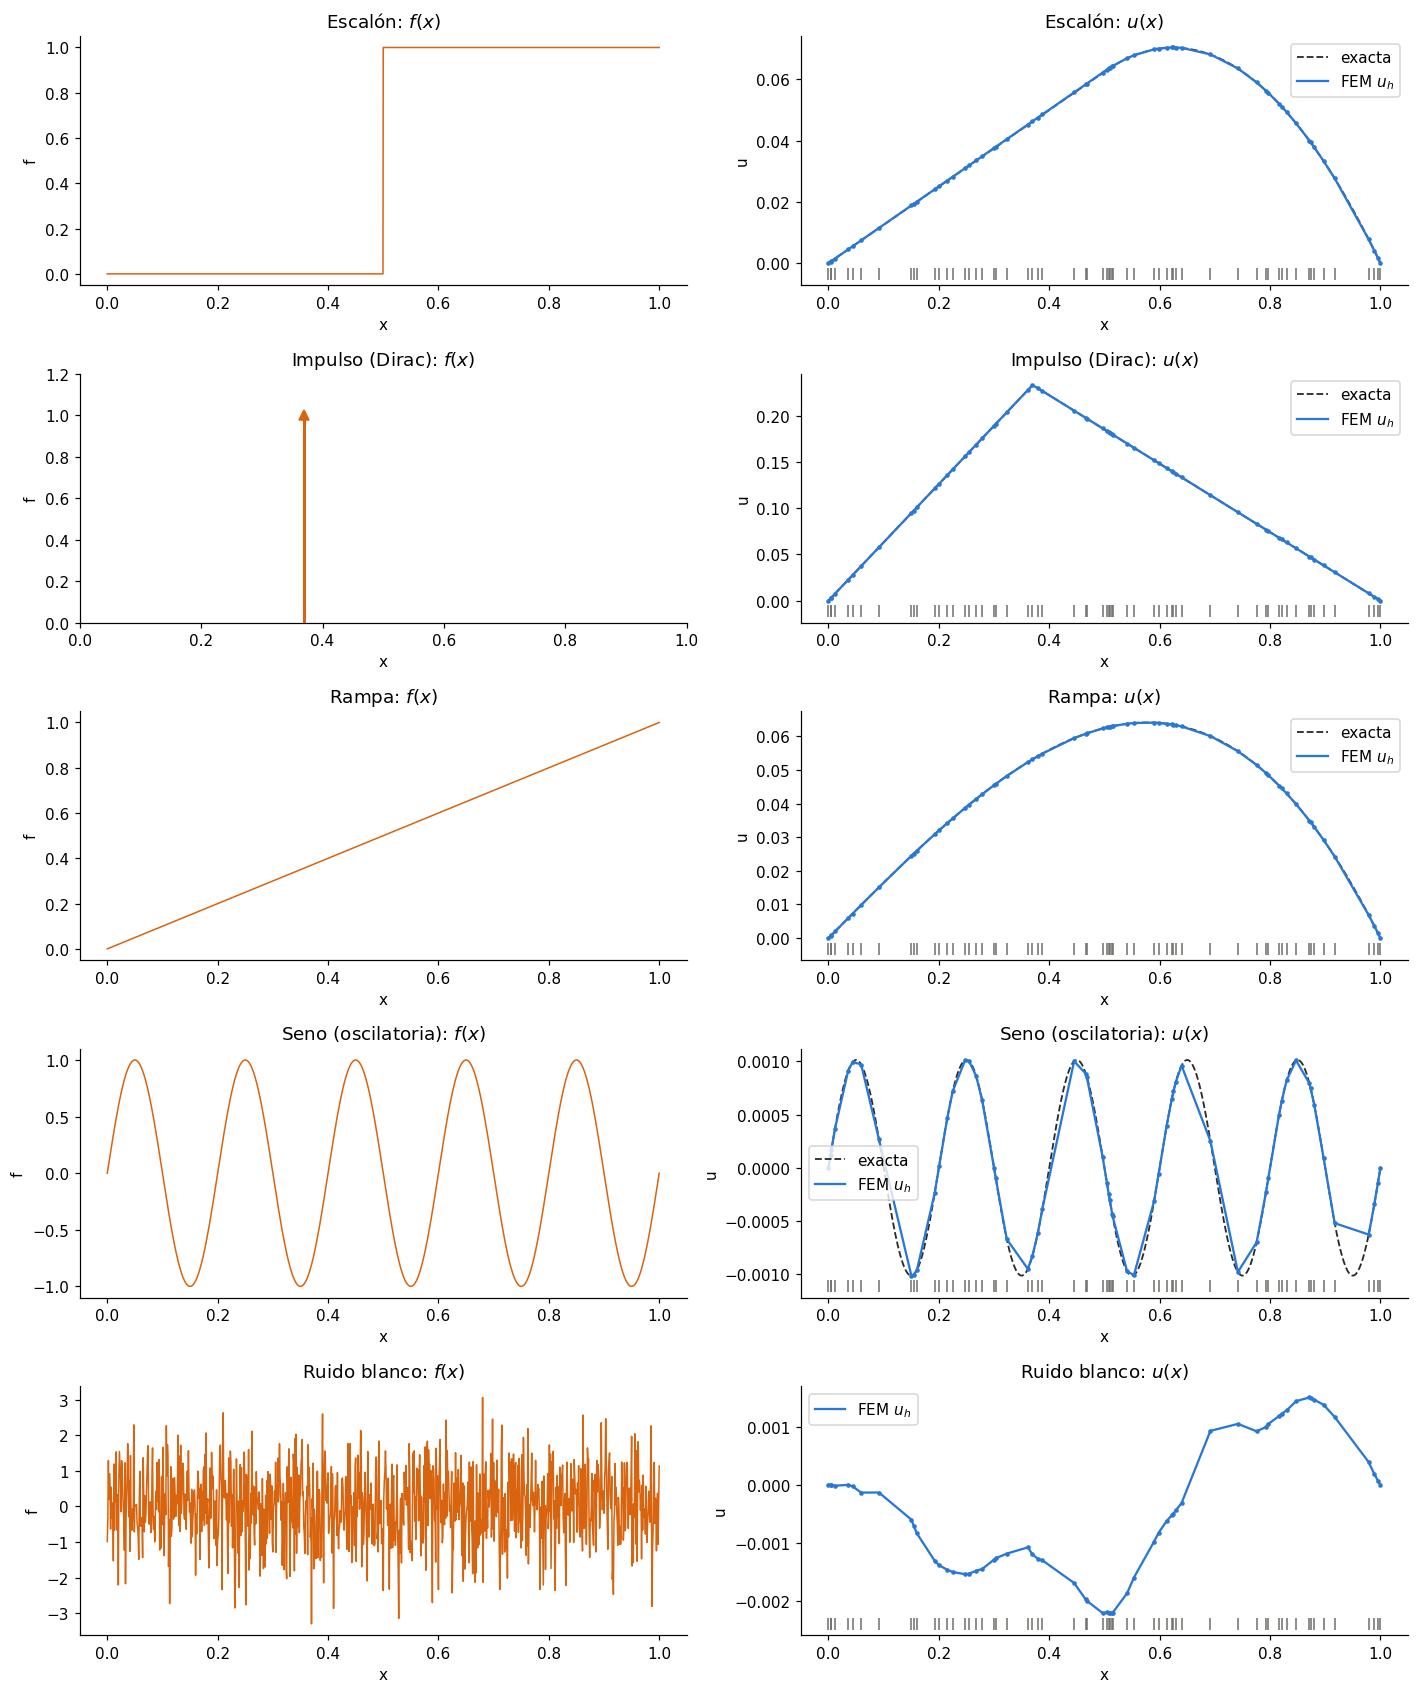

In [11]:
n_extra = 60
nodos2 = generar_malla(n_extra, semilla=7)
xx = np.linspace(0, 1, 2001)

x0 = 0.37 # posición del impulso
k = 5     # frecuencia del seno
rng = np.random.default_rng(123)
malla_ruido = np.linspace(0, 1, 1001)
valores_ruido = rng.normal(0.0, 1.0, malla_ruido.size)

casos = {
    "Escalón": dict(
        f=lambda x: np.where(x >= 0.5, 1.0, 0.0),
        exacta=lambda x: 0.125 * x - 0.5 * np.maximum(x - 0.5, 0.0) ** 2,
    ),
    "Impulso (Dirac)": dict(
        punto=x0,
        exacta=lambda x: np.where(x <= x0, x * (1 - x0), x0 * (1 - x)),
    ),
    "Rampa": dict(
        f=lambda x: x,
        exacta=lambda x: (x - x**3) / 6.0,
    ),
    "Seno (oscilatoria)": dict(
        f=lambda x: np.sin(2 * np.pi * k * x),
        exacta=lambda x: np.sin(2 * np.pi * k * x) / (2 * np.pi * k) ** 2,
    ),
    "Ruido blanco": dict(
        f=lambda x: np.interp(x, malla_ruido, valores_ruido),
        exacta=None,
    ),
}

fig, axes = plt.subplots(len(casos), 2, figsize=(13, 3.1 * len(casos)))

for fila, (nombre, c) in zip(axes, casos.items()):
    if "punto" in c:
        K2, b2, _, _ = ensamblar(nodos2, None)
        b2 += carga_puntual(nodos2, c["punto"])
    else:
        K2, b2, _, _ = ensamblar(nodos2, c["f"], m=5)
    u2 = resolver(K2, b2)

    # izquierda: f(x)
    if "punto" in c:
        fila[0].vlines(c["punto"], 0, 1, color=NARANJA[3], lw=2)
        fila[0].plot(c["punto"], 1, "^", color=NARANJA[3])
        fila[0].set_ylim(0, 1.2)
        fila[0].set_xlim(0, 1)
    else:
        fila[0].plot(xx, c["f"](xx), color=NARANJA[3], lw=1)
    fila[0].set(title=f"{nombre}: $f(x)$", xlabel="x", ylabel="f")

    # derecha: u_h(x) (+ exacta si se conoce) y posición de los nodos
    if c["exacta"] is not None:
        fila[1].plot(xx, c["exacta"](xx), "--", color=TINTA, lw=1.2, label="exacta")
    fila[1].plot(nodos2, u2, "-", color=AZUL[3], lw=1.5, label=r"FEM $u_h$")
    fila[1].plot(nodos2, u2, ".", color=AZUL[3], ms=4)
    fila[1].plot(nodos2, np.full_like(nodos2, u2.min() - 0.05 * np.ptp(u2)), "|", color=GRIS, ms=8)
    fila[1].set(title=f"{nombre}: $u(x)$", xlabel="x", ylabel="u")
    fila[1].legend(loc="best")

plt.tight_layout()
plt.show()

### ¿Qué se observa? (por diversión)

- **Escalón:** $u''=-f$ es discontinua, así que $u$ es lineal en $[0,0.5]$ y parabólica en $[0.5,1]$ (con derivada continua). FEM reproduce bien la forma.
- **Impulso:** $u$ es una función "triangular" o "carpa" (lineal a cada lado de $x_0$) con un **pico agudo** en $x_0$: $u'$ salta en $x_0$ y $u''$ es una Dirac. Con elementos lineales la carpa se representa exactamente en los nodos.
- **Rampa:** la solución es justo el polinomio cúbico del ejemplo de clase $(x-x^3)/6$, que es suave y fácil para la malla.
- **Seno:** $u$ oscila con la misma frecuencia que $f$ pero con amplitud $1/(2\pi k)^2\approx10^{-3}$ (la doble integración suaviza mucho). Donde la malla aleatoria deja huecos grandes, $u_h$ pierde los picos: parece ser que este es el efecto de la resolución de la malla.
- **Ruido blanco:** $u$ resulta suave y pequeña, porque resolver $-u''=f$ actúa como una especie de filtro pasa-bajas o _low-pass_: las altas frecuencias del ruido se atenúan casi por completo.